<a href="https://colab.research.google.com/github/fataei/Computational-Neuroscience/blob/main/last_version_of_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---
# Finetuning CNN using regression loss

- CNN are proven to be a better model of visual cortex, but the goal of visual cortex is not limited to image classification.

- Typically, to model visual cortex responses using CNNs, we -

  1. Extract features of intermediate layers
  2. Reduce dimensionality of the data using techniques like PCA
  3. Perform regression to predict neural data.

- This approach fails to predict all the variance in the data.

**A better approach is to train CNNs directly on the neural response.**

---
# Setup

In [ ]:
# @title Install dependencies
!pip install Pillow --quiet
!pip install git+https://github.com/dicarlolab/CORnet.git
!pip install torch_intermediate_layer_getter --quiet

  Cloning https://github.com/dicarlolab/CORnet.git to /tmp/pip-req-build-6z1yxmye
  Running command git clone --filter=blob:none --quiet https://github.com/dicarlolab/CORnet.git /tmp/pip-req-build-6z1yxmye
  Resolved https://github.com/dicarlolab/CORnet.git to commit d0cc17d4b34ad44dedb01683b70eafd15515adad
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.4/88.4 kB 2.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Using cached nvidia_cuda_nvrtc_cu12-12.1.105-py3-none-manylinux1_x86_64.whl (23.7 MB)
  Using cached nvidia_cuda_runtime_cu12-12.1.105-py3-none-manylinux1_x86_64.whl (823 kB)
  Using cached nvidia_cuda_cupti_cu12-12.1.105-py3-none-manylinux1_x86_64.whl (14.1 MB)
  Using cached nvidia_cudnn_cu12-8.9.2.26-py3-none-manylinux1_x86_64.whl (731.7 MB)
  Using cached nvidia_cublas_cu12-12.1.3.1-py3-none-manylinux1_x86_64.whl (410.6 MB)
  Using cached nvidia_cufft_cu12-11.0.2.54-py3-none-manylinux1_x86_64.whl (121.6 MB)
  Using ca

In [ ]:
#  Imports
import torch
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
from torch import nn, optim
from cornet import cornet_s
from torch_intermediate_layer_getter import IntermediateLayerGetter as MidGetter
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist
from scipy.stats import pearsonr

import copy

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch import nn, optim
from torch.utils.data import Dataset
from torch_intermediate_layer_getter import IntermediateLayerGetter as MidGetter

from torchvision import transforms
import torchvision.models as models


from scipy.spatial.distance import pdist
from scipy.stats import pearsonr


In [ ]:
# @title Downloading Kay dataset
import requests

fnames = ["kay_labels.npy", "kay_labels_val.npy", "kay_images.npz"]

urls =['https://osf.io/r638s/download',
       'https://osf.io/yqb3e/download',
       'https://osf.io/ymnjv/download']

for i, url in enumerate(urls):
  r = requests.get(url, allow_redirects=True)
  with open(fnames[i], 'wb') as fh:
    fh.write(r.content)


with np.load(fnames[2]) as dobj:
  dat = dict(**dobj)
labels = np.load('kay_labels.npy')
val_labels = np.load('kay_labels_val.npy')

In [ ]:
dat["stimuli"].shape

(1750, 128, 128)

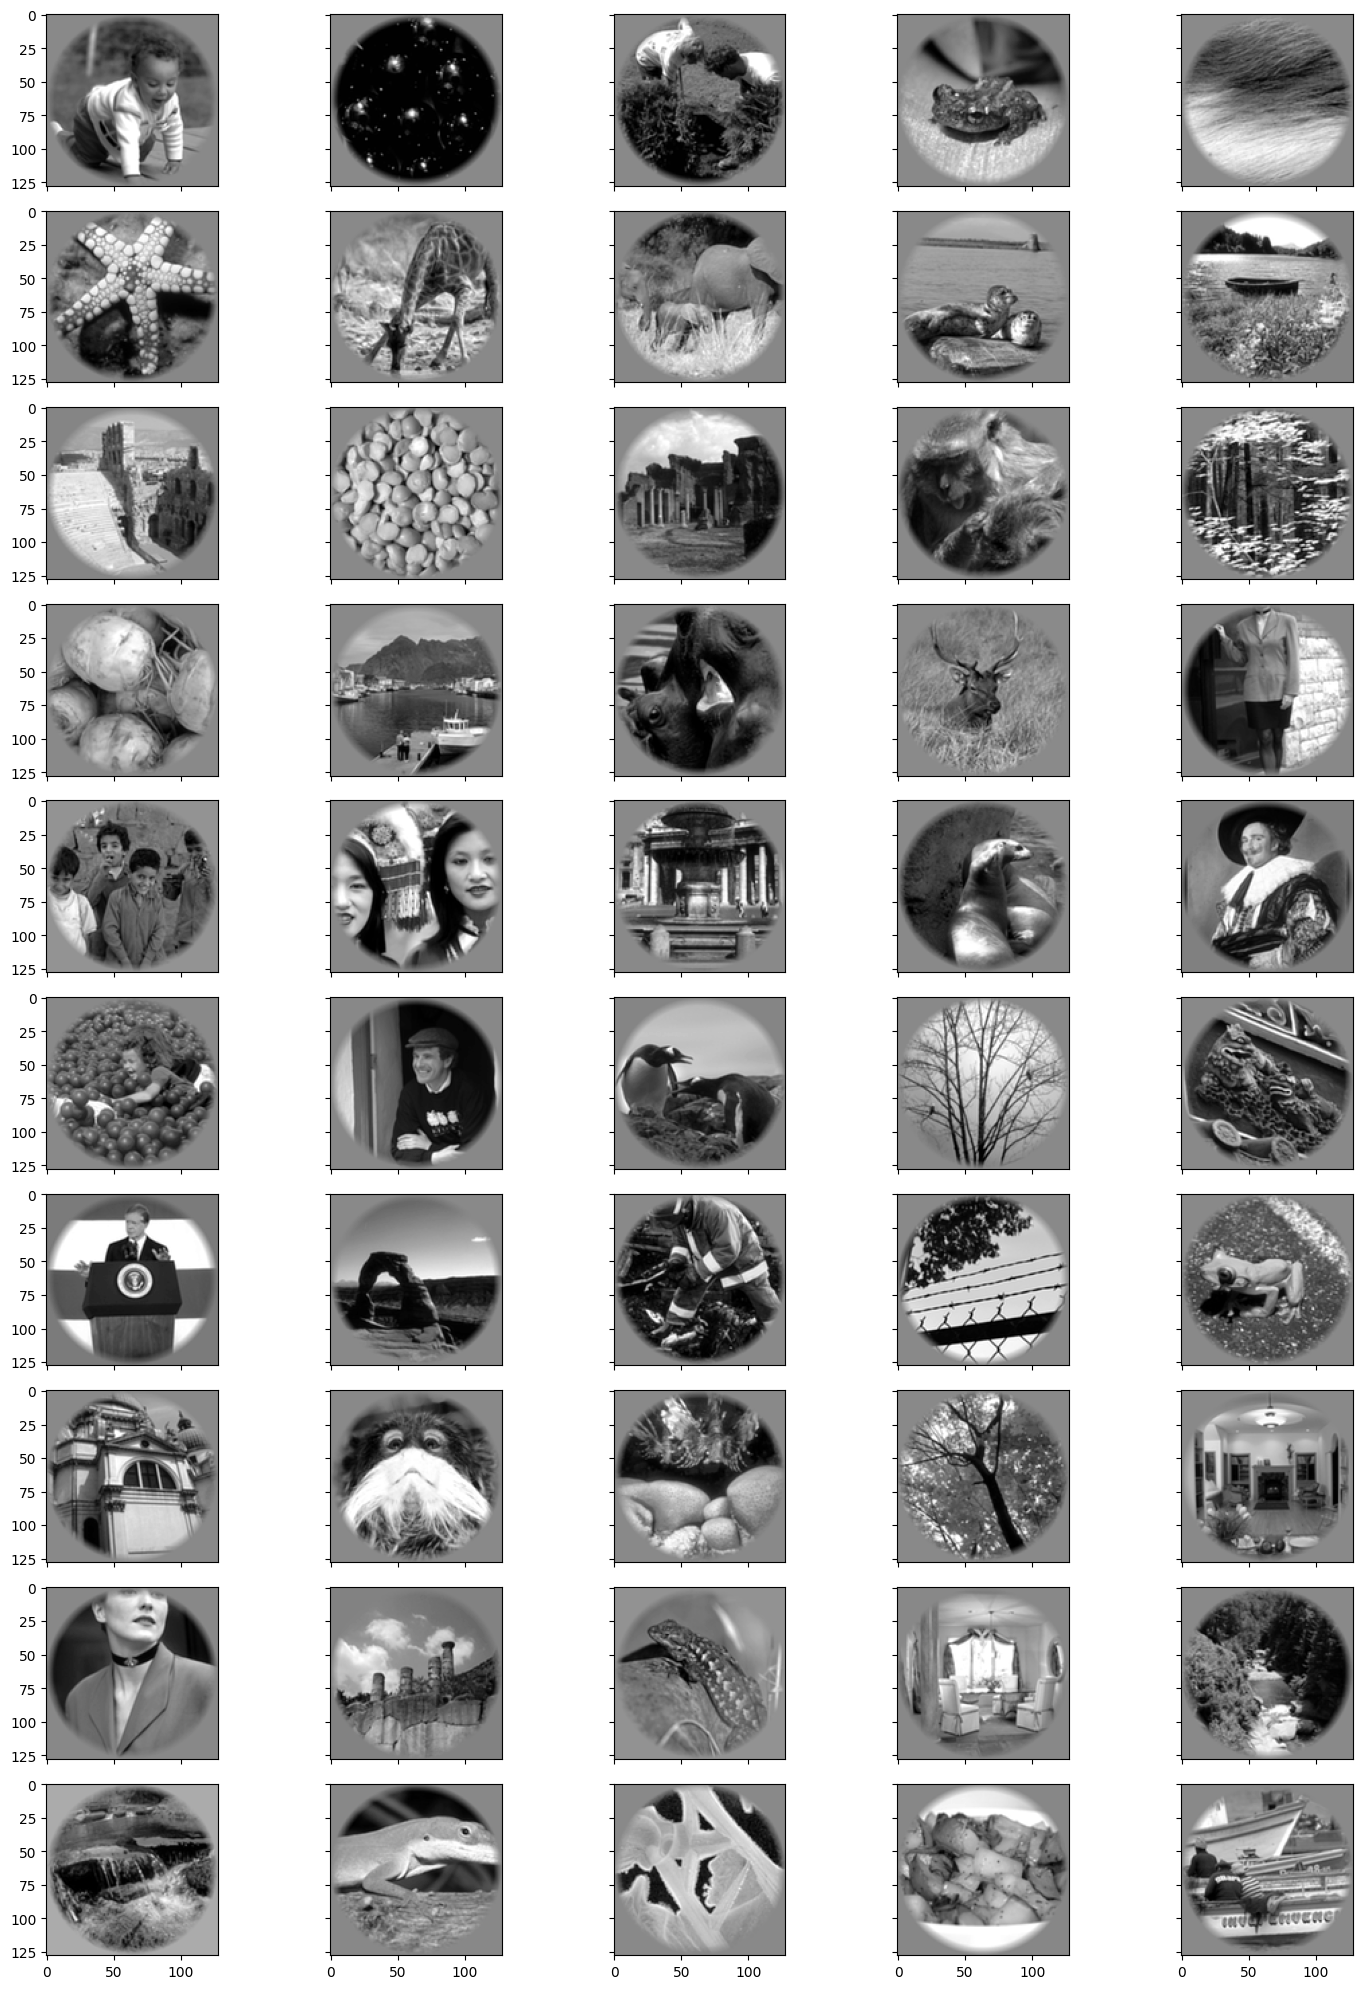

In [ ]:
# @title Visualizing example images
f, axs = plt.subplots(10, 5, figsize=(15, 20), sharex=True, sharey=True)
for ax, im in zip(axs.flat, dat["stimuli"]):
  ax.imshow(im, cmap="gray")
f.tight_layout()
plt.show()

---
# Dataset Structure

`dat` has the following fields:  
- `stimuli`: stim $x_i \, \, x_j$ array of grayscale stimulus images
- `stimuli_test`: stim $x_i \, \, x_j$ array of grayscale stimulus images in the test set  
- `responses`: stim $x$ voxel array of $z$-scored BOLD response amplitude
- `responses_test`:  stim $x$ voxel array of $z$-scored BOLD response amplitude in the test set  
- `roi`: array of voxel labels
- `roi_names`: array of names corresponding to voxel labels

In [ ]:
# Converting stimulus to RGB and changing the scale to 0-255 (Specific to Kay dataset images)
stimuli_tr = dat["stimuli"]
stimuli_ts = dat["stimuli_test"]
stimuli_tr_xformed = np.zeros((1750, 3, 128, 128))
stimuli_ts_xformed = np.zeros((120, 3, 128, 128))
for i in range(1750):
  img = stimuli_tr[i, :, :]
  img = ((img - np.min(img))*255/(np.max(img) - np.min(img))).astype(int)
  stimuli_tr_xformed[i, :, :, :] = [img,img,img]

for i in range(120):
  img = stimuli_ts[i, :, :]
  img = ((img - np.min(img))*255/(np.max(img) - np.min(img))).astype(int)
  stimuli_ts_xformed[i, :, :, :] = [img, img, img]

---
# Fine Tuning AlexNet on voxel activations





In [ ]:
# @title Setting up training and test data for LOC region
loc_id = np.where(dat['roi'] == 7)
response_tr = np.squeeze(dat["responses"][:, loc_id])
response_ts = np.squeeze(dat["responses_test"][:, loc_id])

In [ ]:
# @title Custom dataloader for loading images in numpy array
class MyDataset(Dataset):
  def __init__(self, data, targets, transform=None):
    self.data = data
    self.targets = torch.LongTensor(targets)
    self.transform = transform

  def __getitem__(self, index):
    x = self.data[index]
    y = self.targets[index]

    if self.transform:
        x = Image.fromarray(self.data[index].astype(np.uint8).transpose(1, 2, 0))
        x = self.transform(x)

    return x, y

  def __len__(self):
      return len(self.data)


transform = {
    'train': transforms.Compose([
                                 transforms.RandomResizedCrop(224),
                                 transforms.RandomHorizontalFlip(),
                                 transforms.RandomVerticalFlip(p=0.5),  # new (vertical transform)
                                 transforms.RandomRotation(60),          # new (rotation)
                                 transforms.ToTensor(),
                                 transforms.Normalize([0.485, 0.456, 0.406],
                                                      [0.229, 0.224, 0.225])
                                 ]),
    'val': transforms.Compose([
                               transforms.Resize(256),
                               transforms.CenterCrop(224),
                              # transforms.RandomHorizontalFlip(),       # new (vertical transform)
                              #  transforms.RandomRotation(60),            # new (rotation)
                               transforms.ToTensor(),
                               transforms.Normalize([0.485, 0.456, 0.406],
                                                    [0.229, 0.224, 0.225])
                               ]),
             }

dataset = {}
dataset['train'] = MyDataset(list(stimuli_tr_xformed),
                             list(response_tr), transform=transform['train'])
dataset['val'] = MyDataset(list(stimuli_ts_xformed),
                           list(response_ts), transform=transform['val'])
dataset_sizes = {x: len(dataset[x]) for x in ['train', 'val']}

dataloaders = {x: torch.utils.data.DataLoader(dataset[x], batch_size=50) for x in ['train', 'val']}
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

<ipython-input-8-73c1edb8bb8e>:5: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at ../torch/csrc/utils/tensor_new.cpp:274.)
  self.targets = torch.LongTensor(targets)


In [ ]:
from cornet import cornet_s

In [ ]:
# Training
# device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
net = cornet_s(pretrained=True)
num_ftrs = net.module[4][2].in_features
net.module[4][2] = nn.Linear(num_ftrs, np.shape(response_ts)[1])

net.to(device)
criterion = nn.MSELoss()
learning_rate = 0.1  # Change this
num_epochs =  3 # Change this
optimizer = optim.SGD(net.parameters(), lr=learning_rate, momentum=0.9)



best_model_wts = copy.deepcopy(net.state_dict())
best_loss = 10.0

for epoch in range(num_epochs):
	print(f"Epoch {epoch}/{num_epochs - 1}")
	print('-' * 20)

	# Each epoch has a training and validation phase
	for phase in ['train', 'val']:
		if phase == 'train':
			net.train()  # Set model to training mode
		else:
			net.eval()   # Set model to evaluate mode

		running_loss = 0.0
		running_corrects = 0

		# Iterate over data.
		for inputs, labels in dataloaders[phase]:
			inputs = inputs.to(device)
			labels = labels.to(device)

			# zero the parameter gradients
			optimizer.zero_grad()

			# forward
			# track history if only in train
			with torch.set_grad_enabled(phase == 'train'):
				outputs = net(inputs)
				loss = criterion(outputs.float(), labels.float())

				# backward + optimize only if in training phase
				if phase == 'train':
					loss.backward()
					optimizer.step()

			# statistics
			running_loss += loss.item() * inputs.size(0)

		epoch_loss = running_loss / dataset_sizes[phase]
		print(f"{phase} Loss: {epoch_loss:.4f}")

		# deep copy the model
		if phase == 'val' and epoch_loss < best_loss:
			best_loss = epoch_loss
			best_model_wts = copy.deepcopy(net.state_dict())

	print()

# load best model weights
net.load_state_dict(best_model_wts)

Downloading: "https://s3.amazonaws.com/cornet-models/cornet_s-1d3f7974.pth" to /root/.cache/torch/hub/checkpoints/cornet_s-1d3f7974.pth
100%|██████████| 408M/408M [00:09<00:00, 43.5MB/s]


Epoch 0/2
--------------------
train Loss: 0.5446
val Loss: 0.0605

Epoch 1/2
--------------------
train Loss: 0.4728
val Loss: 0.0539

Epoch 2/2
--------------------
train Loss: 0.4715
val Loss: 0.0531



<All keys matched successfully>

In [ ]:
class MidGetter(nn.Module):
    def __init__(self, model, return_layers, keep_output=False):
        super(MidGetter, self).__init__()
        self.model = model.module if isinstance(model, torch.nn.DataParallel) else model
        self.return_layers = return_layers
        self.keep_output = keep_output
        self._register_hooks()

    def _register_hooks(self):
        self.outputs = {}

        def hook(module, input, output, layer_name):
            self.outputs[layer_name] = output

        for name, layer in self.model.named_modules():
            if name in self.return_layers.values():
                layer.register_forward_hook(lambda m, i, o, n=name: hook(m, i, o, n))

    def forward(self, x):
        self.outputs = {}
        out = self.model(x)
        if self.keep_output:
            self.outputs['output'] = out
        return {key: self.outputs[layer] for key, layer in self.return_layers.items()}, out


In [ ]:
## Extract features of all the intermediate layers from ImageNet-trained and finetuned Alexnet
# return_layers = {
#     'features.2': 'conv1',
#     'features.5': 'conv2',
#     'features.7': 'conv3',
#     'features.9': 'conv4',
#     'features.12': 'conv5',
#     'classifier.1': 'fc1',
#     'classifier.4': 'fc2',
#     'classifier.6': 'fc3',
#     }

return_layers = {
    'V1_output': 'V1',
    'V2_output': 'V2',
    'V4_output': 'V4',
    'IT_output': 'IT',
    'decoder': 'decoder'
}

# Loading AlexNet pretrained on Imagenet
# net_im = models.alexnet(pretrained=True)
net = cornet_s(pretrained=True)
net = torch.nn.DataParallel(net)
net.eval()
net.to(device)


# Setting up feature extraction step
midfeat_ft = MidGetter(net.module, return_layers=return_layers, keep_output=True)
midfeat_im = MidGetter(net.module, return_layers=return_layers, keep_output=True)

# Loading validation data and forward pass through the network
dataloaders = {x: torch.utils.data.DataLoader(dataset[x], batch_size=60) for x in ['val']}
for inputs, labels in dataloaders['val']:
  inputs = inputs.to(device)
  mid_outputs_ft, _ = midfeat_ft(inputs)
  mid_outputs_im, _ = midfeat_im(inputs)

In [ ]:
# @title Dissimilarity - Correlation
# Loading V1 and LOC responses
# v1_id = np.where(dat['roi'] == 1)
# loc_id = np.where(dat['roi'] == 7)
# Rts_v1 = np.squeeze(dat["responses_test"][:, v1_id])
# Rts_lo = np.squeeze(dat["responses_test"][:, loc_id])

# # Observed dissimilarity  - Correlation
# fMRI_dist_metric_ft = "euclidean"  # ['correlation', 'euclidean']
# fMRI_dist_metric_im = "correlation"  # ['correlation', 'euclidean']

# Alexnet_ft_dist_metric = "euclidean"  # ['correlation', 'euclidean']
# Alexnet_im_dist_metric = "correlation"  # ['correlation', 'euclidean']

# dobs_v1_ft = pdist(Rts_v1, fMRI_dist_metric_ft)
# dobs_lo_ft = pdist(Rts_lo, fMRI_dist_metric_ft)
# dobs_v1_im = pdist(Rts_v1, fMRI_dist_metric_im)
# dobs_lo_im = pdist(Rts_lo, fMRI_dist_metric_im)

# # Comparing representation of V1 and LOC across different layers of Alexnet
# r, p = np.zeros((4, len(return_layers))), np.zeros((4, len(return_layers)))
# for i,l in enumerate(mid_outputs_ft.keys()):
#   dnet_ft = pdist(torch.flatten(mid_outputs_ft[l], 1, -1).cpu().detach().numpy(),
#                   Alexnet_ft_dist_metric)
#   dnet_im = pdist(torch.flatten(mid_outputs_im[l], 1, -1).cpu().detach().numpy(),
#                   Alexnet_im_dist_metric)
#   r[0, i], p[0, i] = pearsonr(dnet_ft, dobs_v1_ft)
#   r[1, i], p[1, i] = pearsonr(dnet_im, dobs_v1_im)
#   r[2, i], p[2, i] = pearsonr(dnet_ft, dobs_lo_ft)
#   r[3, i], p[3, i] = pearsonr(dnet_im, dobs_lo_im)

In [ ]:
# import numpy as np
# import torch
# from scipy.spatial.distance import pdist
# from scipy.stats import pearsonr

# # Assuming `dat`, `dataset`, `device`, `net`, `midfeat_ft`, `midfeat_im` are already defined

# # Loading V1 and LOC responses
# v1_id = np.where(dat['roi'] == 1)[0]
# loc_id = np.where(dat['roi'] == 7)[0]

# # Select the first 60 samples from fMRI responses to match the network outputs
# Rts_v1 = np.squeeze(dat["responses_test"][:60, v1_id])
# Rts_lo = np.squeeze(dat["responses_test"][:60, loc_id])

# # Observed dissimilarity - Correlation
# fMRI_dist_metric_ft = "euclidean"  # ['correlation', 'euclidean']
# fMRI_dist_metric_im = "correlation"  # ['correlation', 'euclidean']

# Alexnet_ft_dist_metric = "euclidean"  # ['correlation', 'euclidean']
# Alexnet_im_dist_metric = "correlation"  # ['correlation', 'euclidean']

# dobs_v1_ft = pdist(Rts_v1, fMRI_dist_metric_ft)
# dobs_lo_ft = pdist(Rts_lo, fMRI_dist_metric_ft)
# dobs_v1_im = pdist(Rts_v1, fMRI_dist_metric_im)
# dobs_lo_im = pdist(Rts_lo, fMRI_dist_metric_im)

# # Initialize dataloaders
# dataloaders = {x: torch.utils.data.DataLoader(dataset[x], batch_size=120) for x in ['val']}

# # Forward pass through the network and extract features
# for inputs, labels in dataloaders['val']:
#     inputs = inputs.to(device)
#     mid_outputs_ft, _ = midfeat_ft(inputs)
#     mid_outputs_im, _ = midfeat_im(inputs)
#     break  # Assume we're only using one batch for demonstration purposes

# # Comparing representation of V1 and LOC across different layers of AlexNet
# layers = list(mid_outputs_ft.keys())
# r, p = np.zeros((4, len(layers))), np.zeros((4, len(layers)))

# for i, l in enumerate(layers):
#     # Flatten and convert to numpy arrays
#     flattened_ft = torch.flatten(mid_outputs_ft[l], 1, -1).cpu().detach().numpy()
#     flattened_im = torch.flatten(mid_outputs_im[l], 1, -1).cpu().detach().numpy()

#     # Ensure the flattened arrays have the same length as the observed dissimilarities
#     print(f"Layer {l} - Shape of flattened_ft: {flattened_ft.shape}, Shape of flattened_im: {flattened_im.shape}")

#     # Calculate pairwise distances
#     dnet_ft = pdist(flattened_ft, Alexnet_ft_dist_metric)
#     dnet_im = pdist(flattened_im, Alexnet_im_dist_metric)

#     # Check lengths of the distance matrices and observed dissimilarities
#     print(f"Layer {l} - Length of dnet_ft: {len(dnet_ft)}, Length of dnet_im: {len(dnet_im)}")
#     print(f"Length of dobs_v1_ft: {len(dobs_v1_ft)}, Length of dobs_v1_im: {len(dobs_v1_im)}, Length of dobs_lo_ft: {len(dobs_lo_ft)}, Length of dobs_lo_im: {len(dobs_lo_im)}")

#     # Ensure lengths match before calculating correlations
#     if len(dnet_ft) == len(dobs_v1_ft) and len(dnet_im) == len(dobs_v1_im):
#         r[0, i], p[0, i] = pearsonr(dnet_ft, dobs_v1_ft)
#         r[1, i], p[1, i] = pearsonr(dnet_im, dobs_v1_im)
#         r[2, i], p[2, i] = pearsonr(dnet_ft, dobs_lo_ft)
#         r[3, i], p[3, i] = pearsonr(dnet_im, dobs_lo_im)
#     else:
#         print(f"Skipping layer {l} due to length mismatch.")

# print("Correlation coefficients:", r)
# print("P-values:", p)


## all the 'roi's

In [ ]:
# @title I wanted to see the results for all 'roi's
import numpy as np
import torch
from scipy.spatial.distance import pdist
from scipy.stats import pearsonr

# Assuming `dat`, `dataset`, `device`, `net`, `midfeat_ft`, `midfeat_im` are already defined

# Loading all ROI responses
roi_ids = np.unique(dat['roi'])

# Iterate over each ROI
for roi_id in roi_ids:
    roi_indices = np.where(dat['roi'] == roi_id)[0]

    # Select the first 60 samples from fMRI responses to match the network outputs
    fMRI_responses = np.squeeze(dat["responses_test"][:60, roi_indices])

    # Initialize observed dissimilarities
    dobs = {}
    for metric in ['correlation', 'euclidean']:
        dobs[metric] = pdist(fMRI_responses, metric)

    # Initialize dataloaders
    dataloaders = {x: torch.utils.data.DataLoader(dataset[x], batch_size=60) for x in ['val']}

    # Forward pass through the network and extract features
    for inputs, labels in dataloaders['val']:
        inputs = inputs.to(device)
        mid_outputs_ft, _ = midfeat_ft(inputs)
        mid_outputs_im, _ = midfeat_im(inputs)
        break  # Assume we're only using one batch for demonstration purposes

    # Comparing representation of each ROI across different layers of AlexNet
    layers = list(mid_outputs_ft.keys())
    r, p = np.zeros((4, len(layers))), np.zeros((4, len(layers)))

    for i, l in enumerate(layers):
        # Flatten and convert to numpy arrays
        flattened_ft = torch.flatten(mid_outputs_ft[l], 1, -1).cpu().detach().numpy()
        flattened_im = torch.flatten(mid_outputs_im[l], 1, -1).cpu().detach().numpy()

        # Calculate pairwise distances
        dnet_ft = pdist(flattened_ft, 'euclidean')
        dnet_im = pdist(flattened_im, 'correlation')

        for j, metric in enumerate(dobs.keys()):
            if len(dnet_ft) == len(dobs[metric]):
                r[j, i], p[j, i] = pearsonr(dnet_ft, dobs[metric])
            else:
                print(f"Skipping layer {l} for ROI {roi_id} due to length mismatch for metric {metric}.")

    print(f"Correlation coefficients for ROI {roi_id}:", r)
    print(f"P-values for ROI {roi_id}:", p)

editted


updated code

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy.spatial.distance import pdist
from scipy.stats import pearsonr

# Assuming the following are defined
# dat: dictionary containing your fMRI data
# dataset: dictionary containing your dataset
# device: your computation device (e.g., 'cpu' or 'cuda')
# midfeat_ft, midfeat_im: functions or models that produce the intermediate features
# return_layers: list of layers in the network

# Define roi_ids and layers for this example
roi_ids = [1, 2, 3, 4, 5, 6, 7]  # Example ROI ids
layers = return_layers  # Example layers
mid_outputs_ft = {layer: idx for idx, layer in enumerate(layers)}

plt.figure(figsize=(16, 10))

roi_names = ["ROI " + str(roi_id) for roi_id in roi_ids]
r_all_roi = {}

# Calculate r and p for each ROI
for roi_id in roi_ids:
    roi_indices = np.where(dat['roi'] == roi_id)[0]

    # Select the first 60 samples from fMRI responses to match the network outputs
    fMRI_responses = np.squeeze(dat["responses_test"][:60, roi_indices])

    # Initialize observed dissimilarities
    dobs = {}
    for metric in ['correlation', 'euclidean']:
        dobs[metric] = pdist(fMRI_responses, metric)

    # Initialize dataloaders
    dataloaders = {x: torch.utils.data.DataLoader(dataset[x], batch_size=60) for x in ['val']}

    # Forward pass through the network and extract features
    for inputs, labels in dataloaders['val']:
        inputs = inputs.to(device)
        mid_outputs_ft, _ = midfeat_ft(inputs)
        mid_outputs_im, _ = midfeat_im(inputs)
        break  # Assume we're only using one batch for demonstration purposes

    # Comparing representation of each ROI across different layers of the network
    layers = list(mid_outputs_ft.keys())
    r, p = np.zeros((4, len(layers))), np.zeros((4, len(layers)))

    for i, l in enumerate(layers):
        # Flatten and convert to numpy arrays
        flattened_ft = torch.flatten(mid_outputs_ft[l], 1, -1).cpu().detach().numpy()
        flattened_im = torch.flatten(mid_outputs_im[l], 1, -1).cpu().detach().numpy()

        # Calculate pairwise distances
        dnet_ft = pdist(flattened_ft, 'euclidean')
        dnet_im = pdist(flattened_im, 'correlation')

        for j, metric in enumerate(dobs.keys()):
            if len(dnet_ft) == len(dobs[metric]):
                r[j, i], p[j, i] = pearsonr(dnet_ft, dobs[metric])
            else:
                print(f"Skipping layer {l} for ROI {roi_id} due to length mismatch for metric {metric}.")

    r_all_roi[f"ROI {roi_id}"] = (r, p)
    print(f"Correlation coefficients for ROI {roi_id}:", r)
    print(f"P-values for ROI {roi_id}:", p)

# Plot the results for each ROI
for roi_name in roi_names:
    r, p = r_all_roi[roi_name]

    plt.figure()
    for i in range(4):  # Assuming you have 4 metrics
        plt.bar(range(len(layers)), r[i, :], alpha=0.5)

    plt.legend(['Fine tuned', 'Image Net'])
    plt.ylabel('Correlation coefficient')
    plt.title(f'Match to {roi_name}')
    plt.xticks(range(len(layers)), mid_outputs_ft.keys())
    plt.show()


In [ ]:
# @title plots for all 'roi's
# plt.figure(figsize=(16, 10))

# for roi_name in roi_names:
#     plt.figure()
#     plt.bar(range(len(layers)), r_all_roi[roi_name][0, :], alpha=0.5)
#     plt.bar(range(len(layers)), r_all_roi[roi_name][1, :], alpha=0.5)
#     plt.legend(['Fine Tuned', 'Imagenet'])
#     plt.ylabel('Correlation coefficient')
#     plt.title(f'Match to {roi_name}')
#     plt.xticks(range(len(layers)), mid_outputs_ft.keys())
#     plt.show()

#     # @title plots for all 'roi's
# import matplotlib.pyplot as plt # Import matplotlib

# plt.figure(figsize=(16, 10))

# # Define roi_names based on the roi_ids used in the previous cell
# roi_names = [f"ROI {roi_id}" for roi_id in roi_ids]

# # Initialize a dictionary to store correlation coefficients for all ROIs
# r_all_roi = {}

# for roi_id, roi_name in zip(roi_ids, roi_names):
#     # ... (rest of the code to calculate correlation coefficients for each ROI)
#     r_all_roi[roi_name] = (r, p)  # Store the correlation coefficients for the current ROI

# # Now plot the results
# for roi_name in roi_names:
#     plt.figure()
#     plt.bar(range(len(layers)), r_all_roi[roi_name][0][0, :], alpha=0.5)  # Access the correlation coefficients correctly
#     plt.bar(range(len(layers)), r_all_roi[roi_name][0][1, :], alpha=0.5)  # Access the correlation coefficients correctly
#     plt.legend(['Fine Tuned', 'Imagenet'])
#     plt.ylabel('Correlation coefficient')
#     plt.title(f'Match to {roi_name}')
#     plt.xticks(range(len(layers)), mid_outputs_ft.keys())
#     plt.show()

In [ ]:
# @title Plotting correlation between observed and predicted dissimilarity values
# plt.bar(range(5), r[0, :], alpha=0.5)
# plt.bar(range(5), r[1, :], alpha=0.5)
# plt.legend(['Fine Tuned', 'Imagenet'])
# plt.ylabel('Correlation coefficient')
# plt.title('Match to V1')
# plt.xticks(range(5), mid_outputs_ft.keys())
# plt.show()

# plt.figure()
# plt.bar(range(5), r[2, :], alpha=0.5)
# plt.bar(range(5), r[3, :], alpha=0.5)
# plt.legend(['Fine Tuned', 'Imagenet'])
# plt.ylabel('Correlation coefficient')
# plt.title('Match to LOC')
# plt.xticks(range(5), mid_outputs_ft.keys())
# plt.show()

In [ ]:
def plot_corr_matrix(rdm, ax=None, show=False):
  """Plot dissimilarity matrix

  Args:
    rdm (numpy array): n_stimuli x n_stimuli representational dissimilarity
      matrix
    ax (matplotlib axes): axes onto which to plot

  Returns:
    nothing

  """
  if ax is None:
    ax = plt.gca()
  image = ax.imshow(rdm, vmin=0.0, vmax=2.0)
  ax.set_xticks([])
  ax.set_yticks([])
  cbar = plt.colorbar(image, ax=ax, label='dissimilarity')
  if show:
    plt.show()

def plot_multiple_rdm(rdm_dict):
  """Draw multiple subplots for each RDM in rdm_dict."""
  fig, axs = plt.subplots(1, len(rdm_dict),
                          figsize=(4 * len(resp_dict), 3.5))

  # Compute RDM's for each set of responses and plot
  for i, (label, rdm) in enumerate(rdm_dict.items()):

    image = plot_corr_matrix(rdm, axs)
    axs.set_title(label)
  plt.show()

In [ ]:
from scipy.stats import zscore
def RDM(resp):
  """Compute the representational dissimilarity matrix (RDM)

  Args:
    resp (ndarray): S x N matrix with population responses to
      each stimulus in each row

  Returns:
    ndarray: S x S representational dissimilarity matrix
  """
  #########################################################
  ## TO DO for students: compute representational dissimilarity matrix
  # Fill out function and remove
  # raise NotImplementedError("Student exercise: complete function RDM")
  #########################################################

  # z-score responses to each stimulus
  zresp = zscore(resp, axis=1)

  # Compute RDM
  RDM = 1 - (zresp @ zresp.T) / zresp.shape[1]

  return RDM


# Compute RDMs for each layer
#rdm_dict = {label: RDM(resp) for label, resp in resp_dict.items()}
v1_id = np.where(dat['roi'] == 1)
# loc_id = np.where(dat['roi'] == 7)
Rts_v1 = np.squeeze(dat["responses_test"][:, v1_id])
# Rts_lo = np.squeeze(dat["responses_test"][:, loc_id])
# Plot RDMs
# resp_dict = {}
# resp_dict['V1 data'] = Rts_v1
# plot_multiple_rdm(resp_dict)

print(RDM(Rts_v1).shape)
import seaborn as sns
plt.figure(figsize=(10, 8))
sns.heatmap(RDM(Rts_v1), cmap='viridis', annot=False)
plt.title('Representational Dissimilarity Matrix (RDM)')
plt.xlabel('Stimulus')
plt.ylabel('Stimulus')
plt.show()



In [ ]:
from scipy.stats import zscore
def RDM(resp):
  """Compute the representational dissimilarity matrix (RDM)

  Args:
    resp (ndarray): S x N matrix with population responses to
      each stimulus in each row

  Returns:
    ndarray: S x S representational dissimilarity matrix
  """
  #########################################################
  ## TO DO for students: compute representational dissimilarity matrix
  # Fill out function and remove
  # raise NotImplementedError("Student exercise: complete function RDM")
  #########################################################

  # z-score responses to each stimulus
  zresp = zscore(resp, axis=1)

  # Compute RDM
  RDM = 1 - (zresp @ zresp.T) / zresp.shape[1]

  return RDM


# Compute RDMs for each layer
#rdm_dict = {label: RDM(resp) for label, resp in resp_dict.items()}
v1_id = np.where(dat['roi'] == 1)       # RDM for V1 layer
# loc_id = np.where(dat['roi'] == 7)
Rts_v1 = np.squeeze(dat["responses_test"][:, v1_id])
# Rts_lo = np.squeeze(dat["responses_test"][:, loc_id])
# Plot RDMs
# resp_dict = {}
# resp_dict['V1 data'] = Rts_v1
# plot_multiple_rdm(resp_dict)

print(RDM(Rts_v1).shape)
import seaborn as sns
plt.figure(figsize=(10, 8))
sns.heatmap(RDM(Rts_v1), cmap='viridis', annot=False)
plt.title('Representational Dissimilarity Matrix (RDM)')
plt.xlabel('Stimulus')
plt.ylabel('Stimulus')
plt.show()



In [ ]:
def get_hidden_activity(net, stimuli, layer_labels):
  """Retrieve internal representations of network

  Args:
    net (nn.Module): deep network
    stimuli (torch.Tensor): p x 48 x 64 tensor with stimuli for which to
      compute and retrieve internal representations
    layer_labels (list): list of strings with labels of each layer for which
      to return its internal representations

  Returns:
    dict: internal representations at each layer of the network, in
      numpy arrays. The keys of this dict are the strings in layer_labels.

  """

  # Placeholder
  hidden_activity = {}

  # Attach 'hooks' to each layer of the network to store hidden
  # representations in hidden_activity
  def hook(module, input, output):
    module_label = list(net._modules.keys())[np.argwhere([module == m for m in net._modules.values()])[0, 0]]
    if module_label in layer_labels:  # ignore output layer
      hidden_activity[module_label] = output.view(stimuli.shape[0], -1).detach().numpy()
  hooks = [layer.register_forward_hook(hook) for layer in net.children()]

  # Run stimuli through the network
  pred = net(stimuli)

  # Remove the hooks
  [h.remove() for h in hooks]

  return hidden_activity

In [ ]:
# @title plots for all 'roi's
drive.mount('/content/drive')
# model.to("cpu", non_blocking=True)
# Saving the model weights
torch.save(model.state_dict(), '/content/drive/MyDrive/Colab Notebooks/cornet-s_weights.pth')